# Logistic Regression Model

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Logistic Regression is one of the most widely used supervised learning algorithms for binary classification problems.

In this notebook, a Logistic Regression classifier is trained using the PCA-transformed dataset to predict whether a loan applicant is likely to default.

The objectives of this notebook are to:

- Train a Logistic Regression model.
- Predict loan default.
- Evaluate classification performance.
- Measure model discrimination using ROC-AUC.
- Provide a baseline model for comparison with more advanced machine learning algorithms.

# Import Required Libraries

The following libraries are used for model development, prediction, evaluation, and visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed datasets created during feature engineering are loaded for model training and evaluation.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")

X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()

y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)

print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Dataset Verification

Before training the model, the dimensions of the training and testing datasets are verified.

In [3]:
print("Training Features :", X_train.shape)

print("Testing Features  :", X_test.shape)

print("Training Labels   :", y_train.shape)

print("Testing Labels    :", y_test.shape)

Training Features : (246008, 119)
Testing Features  : (61503, 119)
Training Labels   : (246008,)
Testing Labels    : (61503,)


# Train Logistic Regression Model

A Logistic Regression classifier is trained using the training dataset.

The model learns the relationship between the principal components and the probability of loan default.

In [4]:
# ============================================================
# Train Model
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train,
    y_train
)

print("Model trained successfully.")

Model trained successfully.


# Generate Predictions

The trained model is used to predict both the class labels and the probabilities of default for the testing dataset.

In [5]:
# ============================================================
# Predictions
# ============================================================

y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:,1]

# Model Evaluation

The predictive performance of the Logistic Regression model is evaluated using the following metrics:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

These metrics provide a comprehensive assessment of classification performance.

In [6]:
# ============================================================
# Performance Metrics
# ============================================================

accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred)

recall = recall_score(y_test,y_pred)

f1 = f1_score(y_test,y_pred)

auc = roc_auc_score(y_test,y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.919581
1,Precision,0.552486
2,Recall,0.020141
3,F1-Score,0.038865
4,ROC-AUC,0.758259


# Confusion Matrix

The confusion matrix summarizes the classification results by comparing the predicted labels with the actual labels.

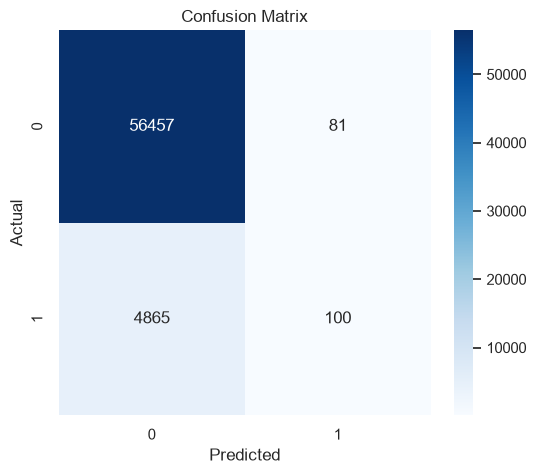

In [7]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

# Classification Report

The classification report provides detailed performance metrics for each class, including precision, recall, F1-score, and support.

In [8]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.55      0.02      0.04      4965

    accuracy                           0.92     61503
   macro avg       0.74      0.51      0.50     61503
weighted avg       0.89      0.92      0.88     61503



# ROC Curve

The Receiver Operating Characteristic (ROC) Curve illustrates the model's ability to distinguish between default and non-default applicants across different classification thresholds.

The Area Under the Curve (AUC) provides a quantitative measure of the model's discriminative performance.

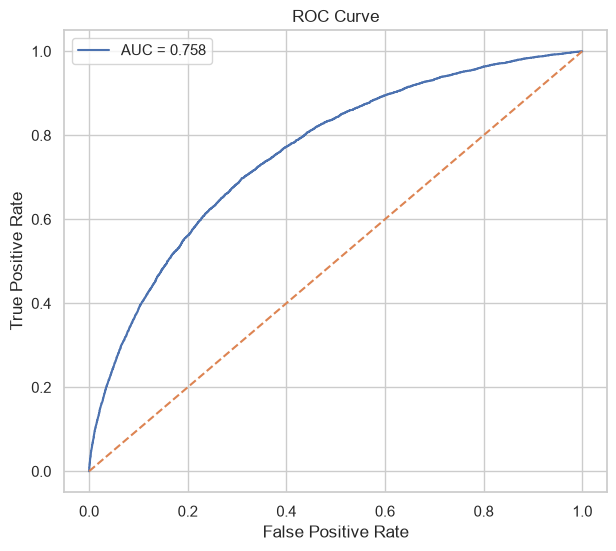

In [9]:
fpr, tpr, _ = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Model Performance Summary

The following table summarizes the predictive performance of the Logistic Regression classifier.

In [10]:
summary = metrics.copy()

summary

,Metric,Value
0,Accuracy,0.919581
1,Precision,0.552486
2,Recall,0.020141
3,F1-Score,0.038865
4,ROC-AUC,0.758259


# Save Trained Logistic Regression Model

The trained Logistic Regression model is saved to disk for later use.

Saving the model allows it to be loaded in the final notebook without retraining, ensuring reproducibility and enabling applicant-level probability prediction for credit risk score generation.

In [14]:
# ============================================================
# Save Trained Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_regression_model.pkl"
)

print("Logistic Regression model saved successfully.")

Logistic Regression model saved successfully.


# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [15]:
# ============================================================
# Save Logistic Regression Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    logistic_model,
    MODEL_DIR / "logistic_regression_model.pkl"
)

print("Logistic Regression model saved successfully.")

Logistic Regression model saved successfully.


# Save Model Performance

To enable a consistent comparison across all machine learning models, the evaluation metrics of the Logistic Regression classifier are saved to a common results file.

If the results file already exists, the current model's metrics are appended. Otherwise, a new file is created.

This approach ensures that the performance of all classification algorithms can be compared using a single consolidated dataset.

In [13]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Logistic Regression"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,0.919581,0.552486,0.020141,0.038865,0.758259,81,4865,100,56457


# Conclusion

The Logistic Regression model was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- The model provides a strong baseline for binary credit risk classification.
- Performance was evaluated using multiple classification metrics, including Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- The ROC Curve demonstrates the model's ability to distinguish between default and non-default applicants.
- The evaluation results obtained in this notebook will serve as a benchmark for comparison with Decision Tree, K-Nearest Neighbors, Naïve Bayes, Random Forest, XGBoost, and LightGBM models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 07 – Decision Tree Classifier**